In [5]:
import numpy as np
import matplotlib.pyplot as plt
import copy
from itertools import product

In [6]:
# GLOBAL STYLE SETTINGS (run once)

plt.rcParams.update({

    # --- FONT SIZES ---
    "font.size": 24,              # base font size
    "axes.titlesize": 20,         # title
    "axes.labelsize": 36,         # x/y labels
    "xtick.labelsize": 36,
    "ytick.labelsize": 36,
    "legend.fontsize": 16,

    # --- LINES ---
    "lines.linewidth": 5,
    "lines.markersize": 16,

    # --- FIGURE / AXIS ---
    "figure.figsize": (8, 6),
    "figure.dpi": 120,
    "axes.linewidth": 1.5,        # thicker axis spines

    # --- TICKS ---
    "xtick.major.size": 15,
    "xtick.major.width": 3,
    "ytick.major.size": 15,
    "ytick.major.width": 3,

    # --- LEGEND ---
    "legend.frameon": True,
    "legend.framealpha": 0.8,
    "legend.fancybox": True,

    # --- GRID (optional) ---
    #"axes.grid": True,
    #"grid.alpha": 0.3,
})


# More than 2 sites

In [7]:
def update(W,x_a,x_b,x_a_tau,x_b_tau,nu=0,dt=0.1): #W a one-hot encoded matrix
    # Calcul des poids avec produits matriciels
    weights_a = {}
    for a in x_a.keys():
        a_vec = np.array(a)  # a_vec est de taille (3,)
        weight_sum = 0
        for b in x_b.keys():
            b_vec = np.array(b)  # b_vec est de taille (2,)
            # Produit : a_vec @ W @ b_vec.T (pour obtenir un scalaire)
            product = a_vec @ W @ b_vec.T
            weight_sum += product * x_b_tau[b]
        weights_a[a] = weight_sum

    weights_b = {}
    for b in x_b.keys():
        b_vec = np.array(b)  # b_vec est de taille (2,)
        weight_sum = 0
        for a in x_a.keys():
            a_vec = np.array(a)  # a_vec est de taille (3,)
            product = a_vec @ W @ b_vec.T
            weight_sum += -product * x_a_tau[a]
        weights_b[b] = weight_sum
    #update x_a and x_b, eccording to exp(weights_a*dt) and weights_b keeping their sum to 1
    # Mise à jour avec exponentielle et normalisation
    exp_weights_a = {a: np.exp(weights_a[a] * dt)*x_a[a] for a in x_a.keys()}
    sum_exp_a = sum(exp_weights_a.values())
    X_a_t = {a: exp_weights_a[a] / sum_exp_a for a in x_a.keys()}
    DGR_a=0
    for a in x_a.keys():
        DGR_a+=X_a_t[a]*nu*dt
        X_a_t[a]-=X_a_t[a]*nu*dt
    for a in x_a.keys():
        X_a_t[a]+=DGR_a/len(x_a)
    exp_weights_b = {b: np.exp(weights_b[b] * dt)*x_b[b] for b in x_b.keys()}
    sum_exp_b = sum(exp_weights_b.values())
    X_b_t = {b: exp_weights_b[b] / sum_exp_b for b in x_b.keys()}
    DGR_b=0
    for b in x_b.keys():
        DGR_b+=X_b_t[b]*nu*dt
        X_b_t[b]-=X_b_t[b]*nu*dt
    for b in x_b.keys():
        X_b_t[b]+=DGR_b/len(x_b)
    return X_a_t,X_b_t

In [8]:
W = 2*np.random.rand(3*4, 3*4)-1  # Matrice aléatoire de taille (3*4,3*4), Q=4 motifs and 3 sites

In [9]:
# Parameters
n_sites = 3
n_motifs = 4

# Generate all possible motif assignments for each site
# Each site has 4 possible motifs (one-hot over 4 positions)
site_motif_blocks = [
    [(0,) * i + (1,) + (0,) * (n_motifs - i - 1) for i in range(n_motifs)]
    for _ in range(n_sites)
]

# Generate all possible sequences (tuples of length n_sites * n_motifs)
keys = list(product(*site_motif_blocks))
keys = [tuple(sum(key, ())) for key in keys]  # Flatten each product into a single tuple

# Initialize x_a and x_b
x_a = {key: np.random.random() for key in keys} #random initial conditions
S = np.sum(list(x_a.values()))
x_a = {a: x_a[a] / S for a in x_a.keys()}

x_b = {key: np.random.random() for key in keys} #random initial conditions
S = np.sum(list(x_b.values()))
x_b = {b: x_b[b] / S for b in x_b.keys()}

In [11]:
f_t_tracked = [[] for i in range(len(keys))]
tau = 10 #the time delay 
dt = 0.1
tau_steps = int(tau / dt) 

x_a_list = [copy.deepcopy(x_a) for _ in range(tau_steps)]
x_b_list = [copy.deepcopy(x_b) for _ in range(tau_steps)]

for t in range(2000):
    x_a_tau = x_a_list[0]
    x_b_tau = x_b_list[0]
    x_a_list = x_a_list[1:]
    x_b_list = x_b_list[1:]

    x_a, x_b = update(W, x_a, x_b, x_a_tau, x_b_tau, nu=0.01, dt=dt)

    x_a_list.append(copy.deepcopy(x_a))
    x_b_list.append(copy.deepcopy(x_b))

    # Track the specific sequence
    for i in range(len(keys)):
        f_t_tracked[i].append(x_b[keys[i]])

Text(0.5, 0, '$t$')

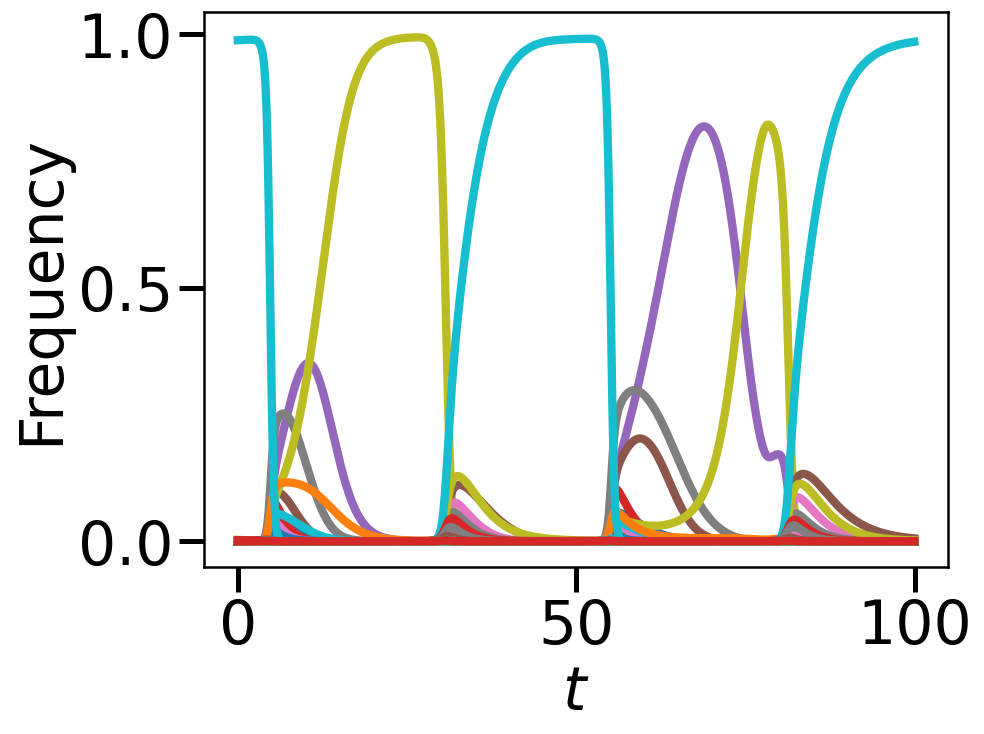

In [12]:
for i in range(len(keys)):
    plt.plot(np.arange(1000)*dt,f_t_tracked[i][-1000:]) # apparemment ça dépend des conditions initiales

plt.ylabel('Frequency')
plt.xlabel(r'$t$')
#plt.savefig('pop_dynamics_extended.svg')